# Named Entity Recognition (NER) on CoNLL-2003
Find and label **people (PER), organizations (ORG), locations (LOC) and miscellaneous entities (MISC)** in English news sentences.

Four models are trained and compared on the same data: **LSTM, BiLSTM, BiLSTM + CRF** (built from scratch in PyTorch, with GloVe + character embeddings) and a fine-tuned **DistilBERT** (HuggingFace).

**How to run:** set `Accelerator = GPU`, `Internet = On`, then press **Run All**. Everything uses PyTorch only (no TensorFlow), so there is no GPU conflict between frameworks.

| Part | What happens |
|---|---|
| 1-3 | Setup, load data, explore |
| 4-5 | Vocabulary, GloVe, character vocabulary, data loaders |
| 6-8 | Build and train LSTM / BiLSTM / BiLSTM+CRF |
| 9 | Fine-tune DistilBERT |
| 10-13 | Compare models, analyse where the CRF helps, demo, save |

## 1) Install, Imports and Settings
- `pytorch-crf` gives us the CRF layer, `seqeval` gives entity-level metrics, `gensim` loads GloVe.
- We use a single GPU (`CUDA_VISIBLE_DEVICES=0`) to avoid multi-GPU surprises.

In [1]:
!pip install -q pytorch-crf seqeval gensim

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"         

import gc, json, copy, random, time
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchcrf import CRF

from seqeval.metrics import classification_report, f1_score, precision_score, recall_score
from seqeval.metrics.sequence_labeling import get_entities


In [3]:
SEED = 42
BATCH = 32
LR = 1e-3
MAX_EPOCHS = 20          # upper limit, early stopping usually ends earlier
PATIENCE = 3             # stop if validation F1 does not improve for 3 epochs
HIDDEN = 128             # LSTM hidden size (per direction)
CHAR_DIM = 30            # character embedding size
CHAR_FILTERS = 50        # character CNN filters
DROPOUT = 0.5
MAX_WORD_LEN = 20        # max characters kept per word

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cuda


## 2) Load the Dataset
CoNLL-2003 (Reuters news). The `eriktks/conll2003` version uses a loading script that newer `datasets` versions no longer support, so the code falls back to `lhoestq/conll2003` automatically.

The labels use the **IOB2** scheme: `B-X` begins an entity of type X, `I-X` continues it, `O` is not an entity. That gives 9 labels. In the fallback version the label names are not stored in the dataset, so we define them in the standard order (checked on the first sentence: `EU` is `B-ORG`, `German` is `B-MISC`).

In [4]:
from datasets import load_dataset

try:
    ds = load_dataset("eriktks/conll2003")
except Exception as e:
    print("eriktks failed:", type(e).__name__, "-> using lhoestq/conll2003")
    ds = load_dataset("lhoestq/conll2003")

LABELS = ["O", "B-PER", "I-PER", "B-ORG", "I-ORG", "B-LOC", "I-LOC", "B-MISC", "I-MISC"]
label2id = {l: i for i, l in enumerate(LABELS)}
id2label = {i: l for l, i in label2id.items()}
NUM_TAGS = len(LABELS)

feat = ds["train"].features["ner_tags"].feature
if hasattr(feat, "names"):
    assert feat.names == LABELS, feat.names      

print(ds)
ex = ds["train"][0]
print(" ".join(f"{t}/{LABELS[g]}" for t, g in zip(ex["tokens"], ex["ner_tags"])))

README.md:   0%|          | 0.00/12.3k [00:00<?, ?B/s]

conll2003.py:   0%|          | 0.00/9.57k [00:00<?, ?B/s]

eriktks failed: RuntimeError -> using lhoestq/conll2003


dataset_infos.json:   0%|          | 0.00/3.67k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.07MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

... (4 outputs left out)

Generating train split:   0%|          | 0/14041 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3250 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/3453 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 14041
    })
    validation: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 3250
    })
    test: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 3453
    })
})
EU/B-ORG rejects/O German/B-MISC call/O to/O boycott/O British/B-MISC lamb/O ./O


## 3) Explore the Data
Most tokens are `O` (not an entity). That is why plain token accuracy is misleading for NER, and why we evaluate with **seqeval** at the entity level later.

'O' share of tokens: 83.3%
Entities in train: {'ORG': 6321, 'MISC': 3438, 'PER': 6600, 'LOC': 7140}


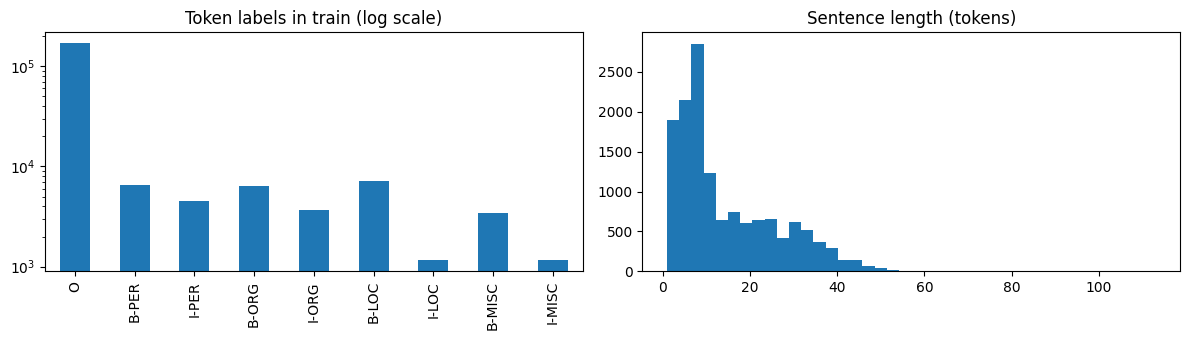

max sentence length: 113


In [5]:
train_tags = [[LABELS[t] for t in seq] for seq in ds["train"]["ner_tags"]]
tag_counts = Counter(t for seq in train_tags for t in seq)
ent_counts = Counter(e[0] for seq in train_tags for e in get_entities(seq))
print(f"'O' share of tokens: {tag_counts['O'] / sum(tag_counts.values()):.1%}")
print("Entities in train:", dict(ent_counts))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
pd.Series(tag_counts).reindex(LABELS).plot(kind="bar", logy=True, ax=ax[0], title="Token labels in train (log scale)")
lengths = [len(s) for s in ds["train"]["tokens"]]
ax[1].hist(lengths, bins=40); ax[1].set_title("Sentence length (tokens)")
plt.tight_layout(); plt.show()
print("max sentence length:", max(lengths))

## 4) Embeddings: GloVe + Characters
**GloVe (pre-trained word vectors).** We download `glove-wiki-gigaword-100` (400,000 words, 100 dimensions) from HuggingFace. GloVe is lowercase, so words are lowercased before lookup. The vectors are **frozen**.

**Character embeddings (for OOV words and capitalization).** Names are often missing from GloVe, and lowercasing throws away the capital letter, which is a strong signal for names. A small character CNN reads the original spelling of each word and produces a vector that is concatenated with the GloVe vector.

In [6]:
from huggingface_hub import hf_hub_download
from gensim.models import KeyedVectors

repo = "fse/glove-wiki-gigaword-100"
model_path = hf_hub_download(repo, "glove-wiki-gigaword-100.model")
hf_hub_download(repo, "glove-wiki-gigaword-100.model.vectors.npy")
glove = KeyedVectors.load(model_path)
print("GloVe words:", len(glove.key_to_index), "| dim:", glove.vector_size)

glove-wiki-gigaword-100.model: reconstructing file:   0%|          |  0.00B / 21.5MB            

glove-wiki-gigaword-100.model: downloading bytes:           |  0.00B            

glove-wiki-gigaword-100.model.vectors.np(…): reconstructing file:   0%|          |  0.00B /  160MB            

glove-wiki-gigaword-100.model.vectors.np(…): downloading bytes:           |  0.00B            

GloVe words: 400000 | dim: 100


In [7]:
EMB_DIM = glove.vector_size
PAD, UNK = 0, 1

# word index: 0 = PAD, 1 = UNK, then the whole GloVe vocabulary
word2idx = {w: i + 2 for i, w in enumerate(glove.index_to_key)}
emb_matrix = np.vstack([
    np.zeros((1, EMB_DIM)),                          # PAD
    glove.vectors.mean(axis=0, keepdims=True),       # UNK = average vector
    glove.vectors,
]).astype("float32")
print("embedding matrix:", emb_matrix.shape)

for split in ["train", "test"]:
    words = [t.lower() for s in ds[split]["tokens"] for t in s]
    print(f"{split}: {np.mean([w in word2idx for w in words]):.1%} of tokens are found in GloVe")

# character index (built from the training set only)
char_counter = Counter(c for s in ds["train"]["tokens"] for t in s for c in t)
char2idx = {c: i + 2 for i, c in enumerate(sorted(char_counter))}
N_CHARS = len(char2idx) + 2
print("characters:", N_CHARS)

embedding matrix: (400002, 100)
train: 97.7% of tokens are found in GloVe
test: 97.1% of tokens are found in GloVe
characters: 86


## 5) Dataset and DataLoaders
Each sentence becomes: word IDs, character IDs per word, and label IDs. Within a batch, everything is padded to the longest sentence. Padded label positions get `-100`, which the loss and metrics ignore.

In [8]:
class NERData(Dataset):
    def __init__(self, split):
        self.tokens = split["tokens"]
        self.tags = split["ner_tags"]
    def __len__(self):
        return len(self.tokens)
    def __getitem__(self, i):
        toks = self.tokens[i]
        words = [word2idx.get(t.lower(), UNK) for t in toks]
        chars = [[char2idx.get(c, UNK) for c in t[:MAX_WORD_LEN]] for t in toks]
        return words, chars, self.tags[i]

def collate(batch):
    B = len(batch)
    T = max(len(b[0]) for b in batch)
    C = max(len(w) for b in batch for w in b[1])
    words = torch.zeros(B, T, dtype=torch.long)
    chars = torch.zeros(B, T, C, dtype=torch.long)
    tags = torch.full((B, T), -100, dtype=torch.long)
    lengths = torch.tensor([len(b[0]) for b in batch])
    for i, (w, c, t) in enumerate(batch):
        n = len(w)
        words[i, :n] = torch.tensor(w)
        tags[i, :n] = torch.tensor(t)
        for j, ch in enumerate(c):
            chars[i, j, :len(ch)] = torch.tensor(ch)
    return words, chars, lengths, tags

train_loader = DataLoader(NERData(ds["train"]), batch_size=BATCH, shuffle=True, collate_fn=collate)
val_loader = DataLoader(NERData(ds["validation"]), batch_size=64, shuffle=False, collate_fn=collate)
test_loader = DataLoader(NERData(ds["test"]), batch_size=64, shuffle=False, collate_fn=collate)

w, c, l, t = next(iter(train_loader))
print(w.shape, c.shape, l.shape, t.shape)

torch.Size([32, 47]) torch.Size([32, 47, 13]) torch.Size([32]) torch.Size([32, 47])


## 6) The Tagger Model
One class builds all three from-scratch models. The only differences are two switches:

| Model | `bidirectional` | `use_crf` |
|---|---|---|
| LSTM | False | False |
| BiLSTM | True | False |
| BiLSTM + CRF | True | True |

**Architecture:** `[GloVe vector ; char-CNN vector] -> dropout -> (Bi)LSTM -> dropout -> Linear (9 scores per word)`.

- **LSTM** reads left to right only. **BiLSTM** reads both directions, so each word sees what comes before and after it.
- **Without CRF** each word picks its best label independently (softmax / cross-entropy), so illegal sequences like `O` followed by `I-PER` can happen.
- **With CRF** the model learns transition scores between labels and decodes the best **whole sequence** (Viterbi), so it learns that `I-PER` can only follow `B-PER` or `I-PER`. This is what improves entity boundaries.

In [9]:
class Tagger(nn.Module):
    def __init__(self, emb_matrix, n_chars, n_tags, bidirectional, use_crf):
        super().__init__()
        self.word_emb = nn.Embedding.from_pretrained(torch.tensor(emb_matrix), freeze=True, padding_idx=0)
        self.char_emb = nn.Embedding(n_chars, CHAR_DIM, padding_idx=0)
        self.char_cnn = nn.Conv1d(CHAR_DIM, CHAR_FILTERS, kernel_size=3, padding=1)
        self.drop = nn.Dropout(DROPOUT)
        self.lstm = nn.LSTM(emb_matrix.shape[1] + CHAR_FILTERS, HIDDEN, batch_first=True, bidirectional=bidirectional)
        self.fc = nn.Linear(HIDDEN * (2 if bidirectional else 1), n_tags)
        self.crf = CRF(n_tags, batch_first=True) if use_crf else None

    @staticmethod
    def make_mask(lengths, T):
        return torch.arange(T, device=lengths.device)[None, :] < lengths[:, None]

    def emissions(self, words, chars, lengths):
        B, T, C = chars.shape
        c = self.char_emb(chars.view(B * T, C)).transpose(1, 2)           # (B*T, CHAR_DIM, C)
        c = torch.relu(self.char_cnn(c)).max(dim=2).values.view(B, T, -1)  # (B, T, CHAR_FILTERS)
        x = self.drop(torch.cat([self.word_emb(words), c], dim=-1))
        packed = nn.utils.rnn.pack_padded_sequence(x, lengths.cpu(), batch_first=True, enforce_sorted=False)
        out, _ = self.lstm(packed)
        out, _ = nn.utils.rnn.pad_packed_sequence(out, batch_first=True, total_length=T)
        return self.fc(self.drop(out))

    def loss(self, words, chars, lengths, tags):
        em = self.emissions(words, chars, lengths)
        if self.crf is not None:
            mask = self.make_mask(lengths, em.size(1))
            return -self.crf(em, tags.clamp(min=0), mask=mask, reduction="token_mean")
        return F.cross_entropy(em.view(-1, em.size(-1)), tags.view(-1), ignore_index=-100)

    @torch.no_grad()
    def predict(self, words, chars, lengths):
        em = self.emissions(words, chars, lengths)
        if self.crf is not None:
            return self.crf.decode(em, mask=self.make_mask(lengths, em.size(1)))
        best = em.argmax(-1).tolist()
        return [seq[:n] for seq, n in zip(best, lengths.tolist())]

m = Tagger(emb_matrix, N_CHARS, NUM_TAGS, bidirectional=True, use_crf=True)
print("trainable parameters:", sum(p.numel() for p in m.parameters() if p.requires_grad))
del m

trainable parameters: 296262


## 7) Training and Evaluation Helpers
- Every epoch we measure **entity-level F1 on the validation set** with seqeval, keep the best weights, and stop early if it does not improve for `PATIENCE` epochs.
- At the end the best weights are evaluated **once** on the test set.
- Predictions are stored so we can analyse errors later.

In [10]:
results, per_type, preds_store, histories = {}, {}, {}, {}

@torch.no_grad()
def predict_loader(model, loader):
    model.eval()
    y_true, y_pred = [], []
    for words, chars, lengths, tags in loader:
        preds = model.predict(words.to(device), chars.to(device), lengths.to(device))
        for p, g, n in zip(preds, tags, lengths.tolist()):
            y_pred.append([LABELS[i] for i in p])
            y_true.append([LABELS[i] for i in g[:n].tolist()])
    return y_true, y_pred

def record(name, y_true, y_pred):
    rep = classification_report(y_true, y_pred, output_dict=True, digits=4)
    results[name] = {"Precision": precision_score(y_true, y_pred),
                     "Recall": recall_score(y_true, y_pred),
                     "F1": f1_score(y_true, y_pred)}
    per_type[name] = {t: rep[t]["f1-score"] for t in ["PER", "ORG", "LOC", "MISC"]}
    preds_store[name] = (y_true, y_pred)
    print(classification_report(y_true, y_pred, digits=4))

def run_tagger(name, bidirectional, use_crf):
    print(f"\n===== {name} =====")
    model = Tagger(emb_matrix, N_CHARS, NUM_TAGS, bidirectional, use_crf).to(device)
    opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=LR)
    best_f1, best_state, bad, history = -1.0, None, 0, []

    for epoch in range(1, MAX_EPOCHS + 1):
        start = time.time()
        model.train()
        total = 0.0
        for words, chars, lengths, tags in train_loader:
            words, chars, lengths, tags = words.to(device), chars.to(device), lengths.to(device), tags.to(device)
            opt.zero_grad()
            loss = model.loss(words, chars, lengths, tags)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step()
            total += loss.item()

        yv_true, yv_pred = predict_loader(model, val_loader)
        val_f1 = f1_score(yv_true, yv_pred)
        history.append(val_f1)
        print(f"epoch {epoch:2d} | train loss {total / len(train_loader):.4f} | val F1 {val_f1:.4f} | {time.time() - start:.0f}s")

        if val_f1 > best_f1:
            best_f1, bad = val_f1, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            bad += 1
            if bad >= PATIENCE:
                print("early stopping")
                break

    model.load_state_dict(best_state)
    y_true, y_pred = predict_loader(model, test_loader)
    record(name, y_true, y_pred)
    histories[name] = history

    del model, opt
    gc.collect(); torch.cuda.empty_cache()

## 8) Train the Three From-Scratch Models

### 8.1 LSTM

In [11]:
run_tagger("LSTM", bidirectional=False, use_crf=False)


===== LSTM =====
epoch  1 | train loss 0.4528 | val F1 0.7511 | 19s
epoch  2 | train loss 0.1972 | val F1 0.7855 | 14s
epoch  3 | train loss 0.1675 | val F1 0.7979 | 14s
epoch  4 | train loss 0.1509 | val F1 0.8183 | 14s
epoch  5 | train loss 0.1392 | val F1 0.8199 | 14s
epoch  6 | train loss 0.1329 | val F1 0.8261 | 14s
epoch  7 | train loss 0.1247 | val F1 0.8360 | 14s
epoch  8 | train loss 0.1207 | val F1 0.8378 | 14s
epoch  9 | train loss 0.1165 | val F1 0.8454 | 14s
epoch 10 | train loss 0.1117 | val F1 0.8471 | 14s
epoch 11 | train loss 0.1089 | val F1 0.8488 | 14s
epoch 12 | train loss 0.1058 | val F1 0.8510 | 14s
epoch 13 | train loss 0.1040 | val F1 0.8521 | 14s
epoch 14 | train loss 0.1009 | val F1 0.8500 | 14s
epoch 15 | train loss 0.0987 | val F1 0.8571 | 14s
epoch 16 | train loss 0.0973 | val F1 0.8567 | 14s
epoch 17 | train loss 0.0956 | val F1 0.8559 | 14s
epoch 18 | train loss 0.0934 | val F1 0.8546 | 14s
early stopping
              precision    recall  f1-score   sup

### 8.2 BiLSTM

In [12]:
run_tagger("BiLSTM", bidirectional=True, use_crf=False)


===== BiLSTM =====
epoch  1 | train loss 0.3762 | val F1 0.8040 | 15s
epoch  2 | train loss 0.1491 | val F1 0.8484 | 15s
epoch  3 | train loss 0.1192 | val F1 0.8679 | 15s
epoch  4 | train loss 0.1041 | val F1 0.8882 | 15s
epoch  5 | train loss 0.0932 | val F1 0.8934 | 15s
epoch  6 | train loss 0.0864 | val F1 0.8997 | 15s
epoch  7 | train loss 0.0795 | val F1 0.9037 | 15s
epoch  8 | train loss 0.0742 | val F1 0.9069 | 15s
epoch  9 | train loss 0.0713 | val F1 0.9062 | 15s
epoch 10 | train loss 0.0679 | val F1 0.9151 | 15s
epoch 11 | train loss 0.0641 | val F1 0.9190 | 15s
epoch 12 | train loss 0.0617 | val F1 0.9173 | 15s
epoch 13 | train loss 0.0590 | val F1 0.9213 | 15s
epoch 14 | train loss 0.0569 | val F1 0.9234 | 15s
epoch 15 | train loss 0.0555 | val F1 0.9222 | 15s
epoch 16 | train loss 0.0538 | val F1 0.9266 | 15s
epoch 17 | train loss 0.0511 | val F1 0.9241 | 15s
epoch 18 | train loss 0.0511 | val F1 0.9241 | 15s
epoch 19 | train loss 0.0490 | val F1 0.9262 | 15s
early stopp

### 8.3 BiLSTM + CRF

In [13]:
run_tagger("BiLSTM+CRF", bidirectional=True, use_crf=True)


===== BiLSTM+CRF =====
epoch  1 | train loss 0.3747 | val F1 0.8224 | 33s
epoch  2 | train loss 0.1403 | val F1 0.8710 | 33s
epoch  3 | train loss 0.1074 | val F1 0.8949 | 33s
epoch  4 | train loss 0.0892 | val F1 0.9054 | 33s
epoch  5 | train loss 0.0778 | val F1 0.9148 | 33s
epoch  6 | train loss 0.0707 | val F1 0.9179 | 33s
epoch  7 | train loss 0.0634 | val F1 0.9218 | 33s
epoch  8 | train loss 0.0591 | val F1 0.9259 | 33s
epoch  9 | train loss 0.0554 | val F1 0.9250 | 33s
epoch 10 | train loss 0.0526 | val F1 0.9322 | 33s
epoch 11 | train loss 0.0494 | val F1 0.9337 | 33s
epoch 12 | train loss 0.0460 | val F1 0.9314 | 33s
epoch 13 | train loss 0.0449 | val F1 0.9355 | 33s
epoch 14 | train loss 0.0415 | val F1 0.9348 | 33s
epoch 15 | train loss 0.0409 | val F1 0.9344 | 33s
epoch 16 | train loss 0.0394 | val F1 0.9380 | 33s
epoch 17 | train loss 0.0378 | val F1 0.9374 | 33s
epoch 18 | train loss 0.0367 | val F1 0.9379 | 33s
epoch 19 | train loss 0.0356 | val F1 0.9416 | 33s
epoch 2

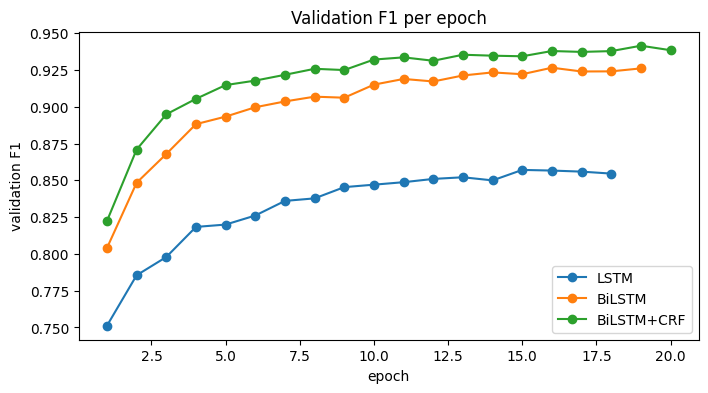

In [14]:
plt.figure(figsize=(8, 4))
for name, h in histories.items():
    plt.plot(range(1, len(h) + 1), h, marker="o", label=name)
plt.xlabel("epoch"); plt.ylabel("validation F1"); plt.title("Validation F1 per epoch"); plt.legend(); plt.show()

## 9) Fine-tune DistilBERT (HuggingFace)
- We use `distilbert-base-cased`. The **cased** version keeps capital letters, which matter a lot for names.
- **Subword alignment:** the tokenizer splits rare words into pieces (for example `Zuckerberg` can become `Zucker` + `##berg`). We give the real label to the **first piece** of each word and `-100` to the other pieces, so they are ignored in the loss and in the metrics. This is the "tokenize and align tokens with labels" step.
- Model: `AutoModelForTokenClassification`, trained with the `Trainer` API for 3 epochs. The best epoch (by validation F1) is kept.

In [15]:
from transformers import (AutoTokenizer, AutoModelForTokenClassification,
                          DataCollatorForTokenClassification, TrainingArguments, Trainer)

BERT_NAME = "distilbert-base-cased"
tok = AutoTokenizer.from_pretrained(BERT_NAME)

def tokenize_and_align(batch):
    enc = tok(batch["tokens"], is_split_into_words=True, truncation=True, max_length=256)
    all_labels = []
    for i, tags in enumerate(batch["ner_tags"]):
        prev, row = None, []
        for wid in enc.word_ids(batch_index=i):
            if wid is None:
                row.append(-100)                 
            elif wid != prev:
                row.append(tags[wid])           
            else:
                row.append(-100)                 
            prev = wid
        all_labels.append(row)
    enc["labels"] = all_labels
    return enc

tok_ds = ds.map(tokenize_and_align, batched=True, remove_columns=ds["train"].column_names)

# example: how one sentence is split and aligned
ids = tok_ds["train"][1]["input_ids"]
print(list(zip(tok.convert_ids_to_tokens(ids), tok_ds["train"][1]["labels"]))[:14])

config.json:   0%|          | 0.00/465 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/436k [00:00<?, ?B/s]

Map:   0%|          | 0/14041 [00:00<?, ? examples/s]

Map:   0%|          | 0/3250 [00:00<?, ? examples/s]

Map:   0%|          | 0/3453 [00:00<?, ? examples/s]

[('[CLS]', -100), ('Peter', 1), ('Blackburn', 2), ('[SEP]', -100)]


In [16]:
def to_tags(pred_ids, label_ids):
    y_true, y_pred = [], []
    for p, l in zip(pred_ids, label_ids):
        keep = l != -100
        y_true.append([LABELS[i] for i in l[keep]])
        y_pred.append([LABELS[i] for i in p[keep]])
    return y_true, y_pred

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    y_true, y_pred = to_tags(logits.argmax(-1), labels)
    return {"precision": precision_score(y_true, y_pred),
            "recall": recall_score(y_true, y_pred),
            "f1": f1_score(y_true, y_pred)}

bert = AutoModelForTokenClassification.from_pretrained(
    BERT_NAME, num_labels=NUM_TAGS, id2label=id2label, label2id=label2id)

args = TrainingArguments(
    output_dir="/kaggle/working/ner_out",
    num_train_epochs=3,
    learning_rate=5e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=64,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    fp16=torch.cuda.is_available(),
    report_to="none",
    seed=SEED,
)

trainer = Trainer(
    model=bert, args=args,
    train_dataset=tok_ds["train"], eval_dataset=tok_ds["validation"],
    data_collator=DataCollatorForTokenClassification(tok),
    compute_metrics=compute_metrics,
)
trainer.train()

model.safetensors: reconstructing file:   0%|          |  0.00B /  263MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForTokenClassification LOAD REPORT from: distilbert-base-cased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Precision,Recall,F1
1,0.142220,0.050893,0.906063,0.915517,0.910765
2,0.026097,0.043646,0.932274,0.938236,0.935246
3,0.010079,0.044025,0.930294,0.941097,0.935665


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=2634, training_loss=0.046844815067386844, metrics={'train_runtime': 104.8369, 'train_samples_per_second': 401.795, 'train_steps_per_second': 25.125, 'total_flos': 525319502290632.0, 'train_loss': 0.046844815067386844, 'epoch': 3.0})

In [17]:
out = trainer.predict(tok_ds["test"])
y_true, y_pred = to_tags(out.predictions.argmax(-1), out.label_ids)

assert sum(map(len, y_true)) == sum(len(s) for s in ds["test"]["tokens"])
record("DistilBERT", y_true, y_pred)

              precision    recall  f1-score   support

         LOC     0.9318    0.9179    0.9248      1668
        MISC     0.7249    0.8219    0.7704       702
         ORG     0.8471    0.8904    0.8682      1661
         PER     0.9621    0.9412    0.9515      1617

   micro avg     0.8859    0.9046    0.8951      5648
   macro avg     0.8665    0.8929    0.8787      5648
weighted avg     0.8898    0.9046    0.8966      5648



## 10) Compare the 4 Models
Entity-level scores on the **test set** (seqeval, micro-averaged over all entities). F1 is the main metric.

,Precision,Recall,F1,PER F1,ORG F1,LOC F1,MISC F1
BiLSTM+CRF,0.9028,0.8994,0.9011,0.9586,0.8726,0.9144,0.8051
DistilBERT,0.8859,0.9046,0.8951,0.9515,0.8682,0.9248,0.7704
BiLSTM,0.8718,0.8982,0.8848,0.9514,0.8525,0.9108,0.7540
LSTM,0.7942,0.8398,0.8164,0.9270,0.7240,0.8612,0.6826


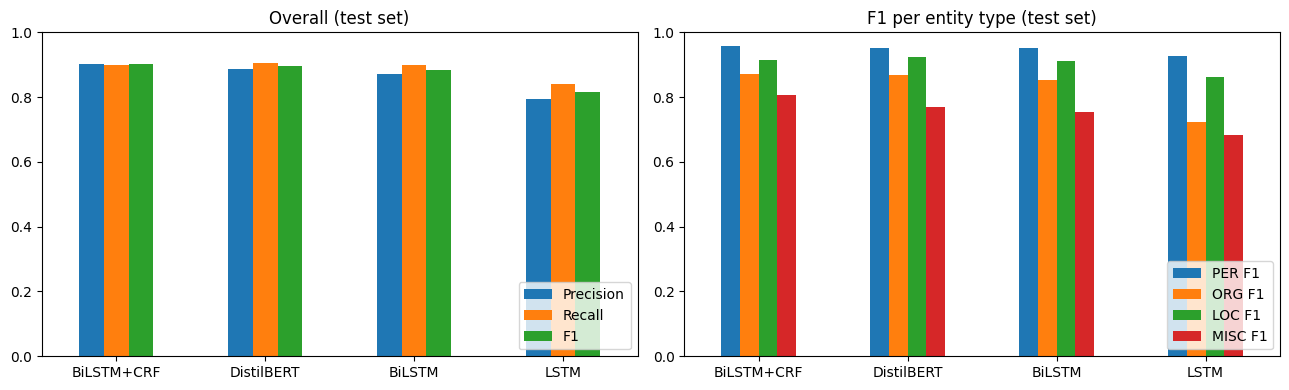

Best model: BiLSTM+CRF


In [18]:
rows = {m: {**results[m], **{f"{t} F1": per_type[m][t] for t in per_type[m]}} for m in results}
res_df = pd.DataFrame(rows).T.round(4).sort_values("F1", ascending=False)
display(res_df)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
res_df[["Precision", "Recall", "F1"]].plot(kind="bar", ax=ax[0], title="Overall (test set)")
res_df[["PER F1", "ORG F1", "LOC F1", "MISC F1"]].plot(kind="bar", ax=ax[1], title="F1 per entity type (test set)")
for a in ax:
    a.set_ylim(0, 1); a.tick_params(axis="x", rotation=0); a.legend(loc="lower right")
plt.tight_layout(); plt.show()
print("Best model:", res_df.index[0])

## 11) Where Does the CRF Improve Boundary Detection?
Two checks, BiLSTM vs BiLSTM + CRF:
1. **Illegal tag sequences**: count `I-X` tags that do not follow a `B-X` or `I-X` of the same type (for example `O` then `I-PER`). A CRF learns to avoid these.
2. **Real examples** where the CRF gets every entity in the sentence right and the plain BiLSTM does not.

In [19]:
def count_invalid(tag_seqs):
    bad = 0
    for seq in tag_seqs:
        prev = "O"
        for t in seq:
            if t.startswith("I-") and prev[2:] != t[2:]:
                bad += 1
            prev = t
    return bad

for name in ["LSTM", "BiLSTM", "BiLSTM+CRF", "DistilBERT"]:
    print(f"{name:12} illegal I- tags in test predictions: {count_invalid(preds_store[name][1])}")

LSTM         illegal I- tags in test predictions: 380
BiLSTM       illegal I- tags in test predictions: 122
BiLSTM+CRF   illegal I- tags in test predictions: 0
DistilBERT   illegal I- tags in test predictions: 69


In [20]:
tokens_test = ds["test"]["tokens"]
gold = preds_store["BiLSTM+CRF"][0]
bi, crf = preds_store["BiLSTM"][1], preds_store["BiLSTM+CRF"][1]

def show(ents, toks):
    return [(t, " ".join(toks[s:e + 1])) for t, s, e in sorted(ents, key=lambda x: x[1])]

crf_only, bi_only, shown = 0, 0, 0
for i, (g, p1, p2) in enumerate(zip(gold, bi, crf)):
    G, E1, E2 = set(get_entities(g)), set(get_entities(p1)), set(get_entities(p2))
    if E2 == G and E1 != G:
        crf_only += 1
        if shown < 5:
            shown += 1
            print("SENTENCE :", " ".join(tokens_test[i]))
            print("  gold only (BiLSTM missed or cut wrongly):", show(G - E1, tokens_test[i]))
            print("  BiLSTM wrongly predicted               :", show(E1 - G, tokens_test[i]))
            print()
    elif E1 == G and E2 != G:
        bi_only += 1

print(f"Sentences where only the CRF is fully correct : {crf_only}")
print(f"Sentences where only the BiLSTM is fully correct: {bi_only}")

SENTENCE : Results of Asian Cup group C matches played on Friday :
  gold only (BiLSTM missed or cut wrongly): []
  BiLSTM wrongly predicted               : [('MISC', 'C')]

SENTENCE : Dutch forward Reggie Blinker had his indefinite suspension lifted by FIFA on Friday and was set to make his Sheffield Wednesday comeback against Liverpool on Saturday .
  gold only (BiLSTM missed or cut wrongly): [('ORG', 'Sheffield Wednesday')]
  BiLSTM wrongly predicted               : [('ORG', 'Sheffield')]

SENTENCE : Group D
  gold only (BiLSTM missed or cut wrongly): []
  BiLSTM wrongly predicted               : [('LOC', 'D')]

SENTENCE : League duties restricted the Barbarians ' selectorial options but they still boast 13 internationals including England full-back Tim Stimpson and recalled wing Tony Underwood , plus All Black forwards Ian Jones and Norm Hewitt .
  gold only (BiLSTM missed or cut wrongly): [('ORG', 'Barbarians')]
  BiLSTM wrongly predicted               : [('MISC', 'Barbarians')]



## 12) Quick Demo with the Fine-tuned DistilBERT
`aggregation_strategy="simple"` merges word pieces and `B-`/`I-` tags into whole entities.

In [21]:
from transformers import pipeline

ner = pipeline("token-classification", model=trainer.model, tokenizer=tok,
               aggregation_strategy="simple", device=0 if torch.cuda.is_available() else -1)

for s in ["Barack Obama visited Google headquarters in California last Tuesday.",
          "Real Madrid beat Manchester United 2-1 in Madrid on Saturday.",
          "Mark Zuckerberg announced that Meta will open a new office in Cairo."]:
    print(s)
    print("  ", [(e["entity_group"], e["word"], round(float(e["score"]), 2)) for e in ner(s)])

Barack Obama visited Google headquarters in California last Tuesday.
   [('PER', 'Barack Obama', 0.96), ('ORG', 'Google', 1.0), ('LOC', 'California', 1.0)]
Real Madrid beat Manchester United 2-1 in Madrid on Saturday.
   [('ORG', 'Real Madrid', 1.0), ('ORG', 'Manchester United', 1.0), ('LOC', 'Madrid', 1.0)]
Mark Zuckerberg announced that Meta will open a new office in Cairo.
   [('PER', 'Mark Zuckerberg', 0.86), ('ORG', 'Meta', 1.0), ('LOC', 'Cairo', 1.0)]


## 13) Save the Model and Results
The fine-tuned DistilBERT is saved in `/kaggle/working/ner_model`. It is the model we will use in the Gradio app (`app.py`), which highlights the entities with colors.

In [22]:
trainer.save_model("/kaggle/working/ner_model")
tok.save_pretrained("/kaggle/working/ner_model")
res_df.to_csv("/kaggle/working/ner_results.csv")
print(os.listdir("/kaggle/working/ner_model"))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

['tokenizer.json', 'model.safetensors', 'config.json', 'training_args.bin', 'tokenizer_config.json']
